In [ ]:
%pip install scikit-learn==1.7.2

In [1]:
from gyraze_conv_MPE_surrogate import surrogate_model
print(surrogate_model(0, 6.4220753,	3.063950063,	6.349612))

4.045207977294922


Plotted 3317 rows; omitted 1 rows with missing plot values.


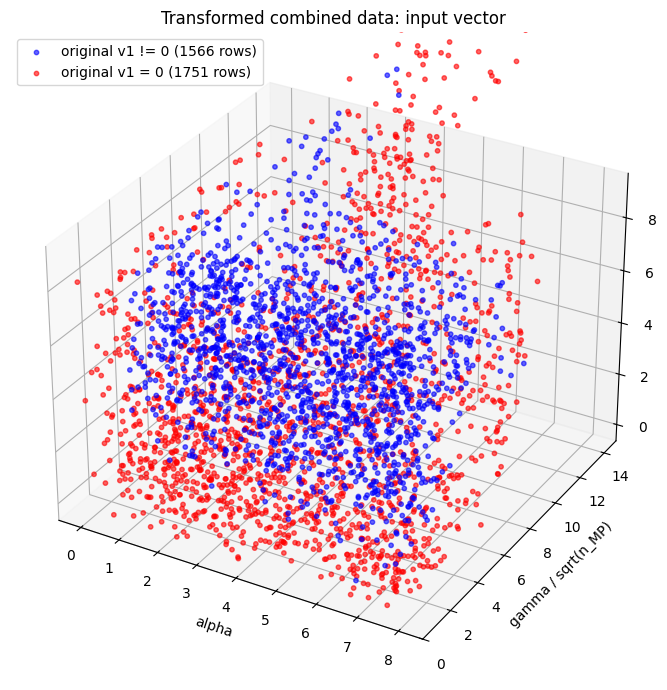

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

# The CSV contains gamma/sqrt(n_MP) and sqrt(vi**2 - 2*phi_MP).
data = pd.read_csv("101326combined.csv")
original_v1 = pd.read_csv("combined.csv", usecols=["v1"])["v1"]
assert len(data) == len(original_v1), "Original and transformed CSV rows must align."
input_columns = list(data.columns[:3])
plot_data = data.assign(original_v1=original_v1).dropna(subset=input_columns + ["original_v1"])

# Color using original v1; coordinates use the transformed CSV.
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection="3d")
for mask, color, label in [
    (plot_data["original_v1"] != 0, "blue", "original v1 != 0"),
    (plot_data["original_v1"] == 0, "red", "original v1 = 0"),
]:
    points = plot_data.loc[mask, input_columns]
    ax.scatter(points.iloc[:, 0], points.iloc[:, 1], points.iloc[:, 2],
               c=color, s=10, alpha=0.6, label=f"{label} ({len(points)} rows)")
ax.set_xlabel(input_columns[0])
ax.set_ylabel("gamma / sqrt(n_MP)")
ax.set_ylim(0, 15)
ax.set_zlabel(input_columns[2])
ax.set_title("Transformed combined data: input vector")
ax.legend()
fig.tight_layout()
print(f"Plotted {len(plot_data)} rows; omitted {len(data) - len(plot_data)} rows with missing plot values.")
plt.show()


Saved SVM boundary: 31200 triangles; gamma window [0, 15].
Plotted 3317 rows; omitted 1 rows with missing plot values.


/home1/cwarme/.conda/envs/focex-gpu/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


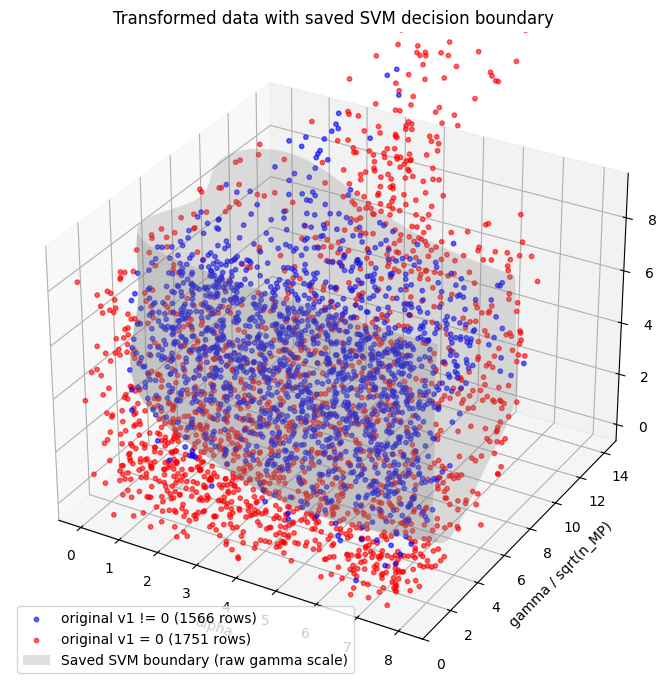

In [3]:
import pandas as pd
import numpy as np
import joblib
from mpl_toolkits.mplot3d.art3d import Poly3DCollection
from matplotlib.patches import Patch
import matplotlib.pyplot as plt

# The CSV contains gamma/sqrt(n_MP) and sqrt(vi**2 - 2*phi_MP).
data = pd.read_csv("101326combined.csv")
original_v1 = pd.read_csv("combined.csv", usecols=["v1"])["v1"]
assert len(data) == len(original_v1), "Original and transformed CSV rows must align."
input_columns = list(data.columns[:3])
plot_data = data.assign(original_v1=original_v1).dropna(subset=input_columns + ["original_v1"])

# Color using original v1; coordinates use the transformed CSV.
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection="3d")
for mask, color, label in [
    (plot_data["original_v1"] != 0, "blue", "original v1 != 0"),
    (plot_data["original_v1"] == 0, "red", "original v1 = 0"),
]:
    points = plot_data.loc[mask, input_columns]
    ax.scatter(points.iloc[:, 0], points.iloc[:, 1], points.iloc[:, 2],
               c=color, s=10, alpha=0.6, label=f"{label} ({len(points)} rows)")
ax.set_xlabel(input_columns[0])
ax.set_ylabel("gamma / sqrt(n_MP)")
ax.set_ylim(0, 15)
ax.set_zlabel(input_columns[2])
# Preserve the exact data-plot window before adding the boundary.
plot_bounds = np.array([ax.get_xlim(), ax.get_ylim(), ax.get_zlim()])
clf = joblib.load("svm_model.pkl")
assert clf.n_features_in_ == 3
# The saved SVM was trained on raw alpha, gamma, phi_wall.
# Evaluate it directly here; the scatter uses transformed gamma.
resolution = 45
axes_grid = [np.linspace(lo, hi, resolution) for lo, hi in plot_bounds]
grid = np.stack(np.meshgrid(*axes_grid, indexing="ij"), axis=-1)
flat_grid = grid.reshape(-1, 3)
decision = np.concatenate([
    clf.decision_function(flat_grid[start:start + 10000])
    for start in range(0, len(flat_grid), 10000)
]).reshape(grid.shape[:-1])

# Extract decision_function == 0 using marching tetrahedra.
# This uses NumPy only, so no additional plotting package is required.
corners = np.array([[0,0,0], [1,0,0], [1,1,0], [0,1,0],
                    [0,0,1], [1,0,1], [1,1,1], [0,1,1]])
tetrahedra = [[0,1,2,6], [0,2,3,6], [0,3,7,6],
              [0,7,4,6], [0,4,5,6], [0,5,1,6]]
cube_points = np.stack([
    grid[a:a+resolution-1, b:b+resolution-1, c:c+resolution-1].reshape(-1, 3)
    for a,b,c in corners
], axis=1)
cube_values = np.stack([
    decision[a:a+resolution-1, b:b+resolution-1, c:c+resolution-1].ravel()
    for a,b,c in corners
], axis=1)
triangles = []
for tetrahedron in tetrahedra:
    points = cube_points[:, tetrahedron]
    values = cube_values[:, tetrahedron]
    positive = values >= 0
    codes = positive @ np.array([1, 2, 4, 8])
    for code in range(1, 15):
        selected = codes == code
        if not selected.any():
            continue
        inside = [i for i in range(4) if code & (1 << i)]
        outside = [i for i in range(4) if not code & (1 << i)]
        p, v = points[selected], values[selected]
        def crossing(i, j):
            fraction = v[:, i] / (v[:, i] - v[:, j])
            return p[:, i] + fraction[:, None] * (p[:, j] - p[:, i])
        if len(inside) == 1 or len(outside) == 1:
            singleton, others = (inside, outside) if len(inside) == 1 else (outside, inside)
            triangles.append(np.stack([crossing(singleton[0], j) for j in others], axis=1))
        else:
            a, b = inside
            c, d = outside
            ac, ad, bc, bd = crossing(a,c), crossing(a,d), crossing(b,c), crossing(b,d)
            triangles.extend([np.stack([ac, ad, bc], axis=1), np.stack([ad, bd, bc], axis=1)])
if not triangles:
    raise ValueError("The saved SVM has no zero decision surface in this plot window.")
boundary_triangles = np.concatenate(triangles)
surface = Poly3DCollection(boundary_triangles, facecolor="gray", edgecolor="none", alpha=0.25)
ax.add_collection3d(surface)
ax.set_xlim(*plot_bounds[0])
ax.set_ylim(*plot_bounds[1])
ax.set_zlim(*plot_bounds[2])
handles, labels = ax.get_legend_handles_labels()
handles.append(Patch(facecolor="gray", alpha=0.25))
labels.append("Saved SVM boundary (raw gamma scale)")
ax.legend(handles, labels)
print(f"Saved SVM boundary: {len(boundary_triangles)} triangles; gamma window [0, 15].")
ax.set_title("Transformed data with saved SVM decision boundary")
fig.tight_layout()
print(f"Plotted {len(plot_data)} rows; omitted {len(data) - len(plot_data)} rows with missing plot values.")
plt.show()


SVM decision >= 0: 1364 points; 1340 blue, 24 red.
SVM decision < 0: 1953 points; 226 blue, 1727 red.


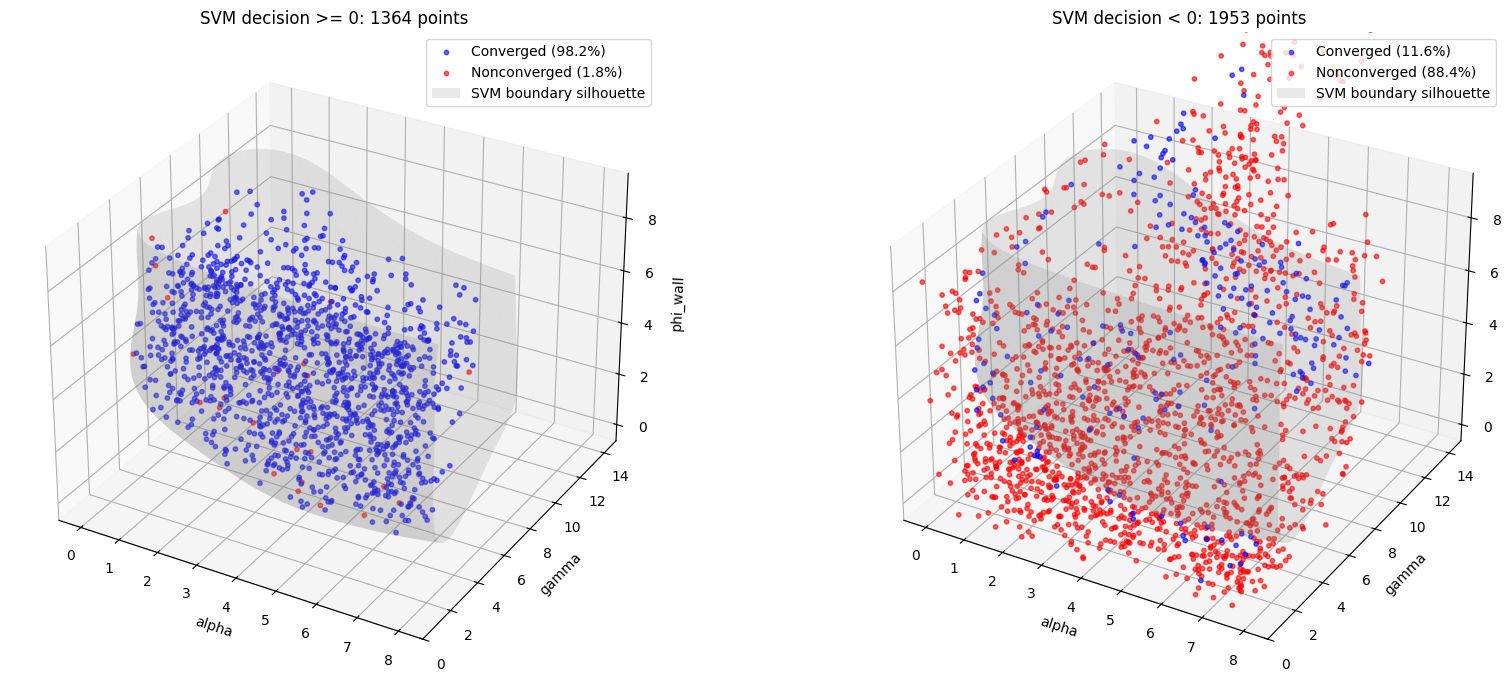

In [4]:
# Run the SVM boundary plot cell above first.
# Split in the same displayed coordinates used to evaluate that boundary.
split_points = plot_data.copy()
split_points["svm_decision"] = clf.decision_function(split_points[input_columns].to_numpy())
fig_split = plt.figure(figsize=(18, 7))
side_definitions = [
    (split_points["svm_decision"] >= 0, "SVM decision >= 0"),
    (split_points["svm_decision"] < 0, "SVM decision < 0"),
]
for panel, (side_mask, side_label) in enumerate(side_definitions, start=1):
    side_points = split_points.loc[side_mask]
    side_ax = fig_split.add_subplot(1, 2, panel, projection="3d")
    side_ax.add_collection3d(Poly3DCollection(
        boundary_triangles, facecolor="gray", edgecolor="none", alpha=0.18
    ))
    for color_mask, color, label in [
        (side_points["original_v1"] != 0, "blue", "Converged"),
        (side_points["original_v1"] == 0, "red", "Nonconverged"),
    ]:
        points = side_points.loc[color_mask, input_columns]
        side_ax.scatter(points.iloc[:, 0], points.iloc[:, 1], points.iloc[:, 2],
                        c=color, s=10, alpha=0.6, label=f"{label} ({(100 * len(points) / len(side_points) if len(side_points) else 0):.1f}%)")
    side_ax.set_xlim(*plot_bounds[0])
    side_ax.set_ylim(*plot_bounds[1])
    side_ax.set_zlim(*plot_bounds[2])
    side_ax.view_init(elev=ax.elev, azim=ax.azim)
    side_ax.set_xlabel(input_columns[0])
    side_ax.set_ylabel("gamma")
    side_ax.set_zlabel(input_columns[2])
    side_ax.set_title(f"{side_label}: {len(side_points)} points")
    handles, labels = side_ax.get_legend_handles_labels()
    handles.append(Patch(facecolor="gray", alpha=0.18))
    labels.append("SVM boundary silhouette")
    side_ax.legend(handles, labels, loc="upper right")
    print(f"{side_label}: {len(side_points)} points; "
          f"{(side_points.original_v1 != 0).sum()} blue, "
          f"{(side_points.original_v1 == 0).sum()} red.")
assert sum(int(mask.sum()) for mask, _ in side_definitions) == len(split_points)
fig_split.tight_layout()
fig_split.savefig("svm_boundary_split.png", dpi=300, bbox_inches="tight")
plt.show()


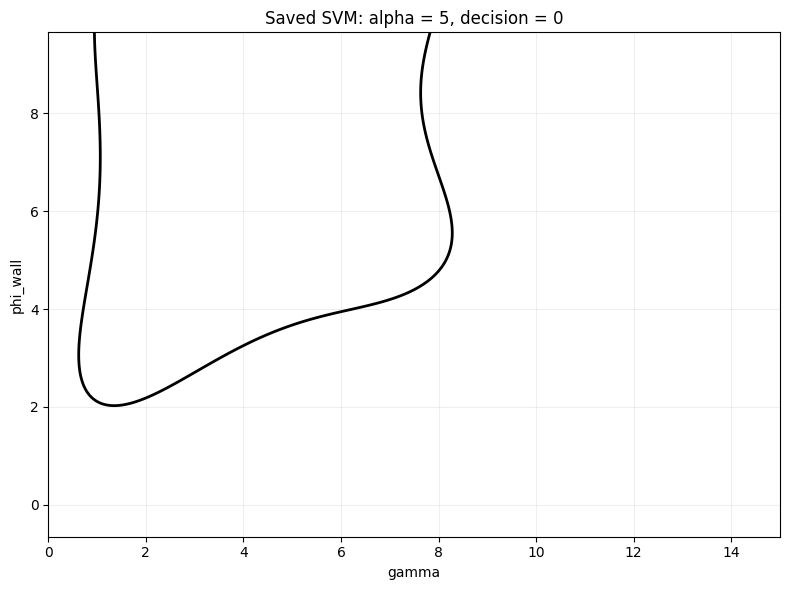

In [5]:
import numpy as np
import joblib
import matplotlib.pyplot as plt

# Run the 3D boundary plot cell first to define its exact plot_bounds.
# Edit these settings and rerun this cell.
fixed_variable = "alpha"  # "alpha", "gamma", or "phi_wall"
fixed_value = 5
boundary_level = 0.0  # Zero is the SVM decision boundary.
slice_resolution = 250

svm_features = ["alpha", "gamma", "phi_wall"]
if fixed_variable not in svm_features:
    raise ValueError(f"Choose one of {svm_features}.")
fixed_index = svm_features.index(fixed_variable)
if not plot_bounds[fixed_index, 0] <= fixed_value <= plot_bounds[fixed_index, 1]:
    raise ValueError(f"{fixed_variable} must be within {plot_bounds[fixed_index].tolist()}.")
free_indices = [i for i in range(3) if i != fixed_index]
u, v = [np.linspace(*plot_bounds[i], slice_resolution) for i in free_indices]
UU, VV = np.meshgrid(u, v)
slice_inputs = np.empty((UU.size, 3))
slice_inputs[:, fixed_index] = fixed_value
slice_inputs[:, free_indices[0]] = UU.ravel()
slice_inputs[:, free_indices[1]] = VV.ravel()
slice_clf = joblib.load("svm_model.pkl")
slice_decision = slice_clf.decision_function(slice_inputs).reshape(UU.shape)

fig_slice, ax_slice = plt.subplots(figsize=(8, 6))
if slice_decision.min() < boundary_level < slice_decision.max():
    slice_contour = ax_slice.contour(UU, VV, slice_decision,
                                    levels=[boundary_level], colors="black", linewidths=2)
else:
    ax_slice.text(0.5, 0.5, "No boundary at this slice and level",
                  transform=ax_slice.transAxes, ha="center", va="center")
ax_slice.set_xlim(*plot_bounds[free_indices[0]])
ax_slice.set_ylim(*plot_bounds[free_indices[1]])
ax_slice.set_xlabel(svm_features[free_indices[0]])
ax_slice.set_ylabel(svm_features[free_indices[1]])
ax_slice.set_title(f"Saved SVM: {fixed_variable} = {fixed_value:g}, decision = {boundary_level:g}")
# This saved SVM uses raw gamma, matching the boundary overlay above.
ax_slice.grid(alpha=0.2)
fig_slice.tight_layout()
plt.show()


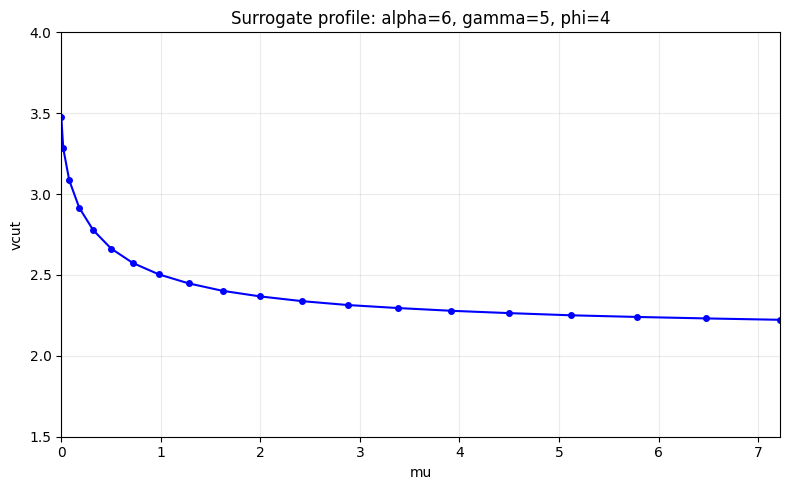

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from gyraze_conv_MPE_surrogate import surrogate_model, vvec as mu_grid

# Edit these inputs and rerun. Defaults match the initial surrogate call.
profile_alpha = 6
profile_gamma = 5
profile_phi = 4

# Evaluate all 20 vcuts at the exact mu grid defined by the model module.
vcuts = np.asarray(surrogate_model(mu_grid, profile_alpha, profile_gamma, profile_phi))
assert vcuts.shape == mu_grid.shape
fig_profile, ax_profile = plt.subplots(figsize=(8, 5))
ax_profile.plot(mu_grid, vcuts, "o-", color="blue", markersize=4)
ax_profile.set_xlabel("mu")
ax_profile.set_ylabel("vcut")
ax_profile.set_title(
    f"Surrogate profile: alpha={profile_alpha:g}, gamma={profile_gamma:g}, phi={profile_phi:g}"
)
ax_profile.set_xlim(mu_grid[0], mu_grid[-1])
ax_profile.set_ylim(1.5, 4)
ax_profile.grid(alpha=0.25)
fig_profile.tight_layout()
plt.show()


alpha sampled within [-0.5816525291666667, 8.583866929166664].
gamma sampled within [0.0, 15.0].


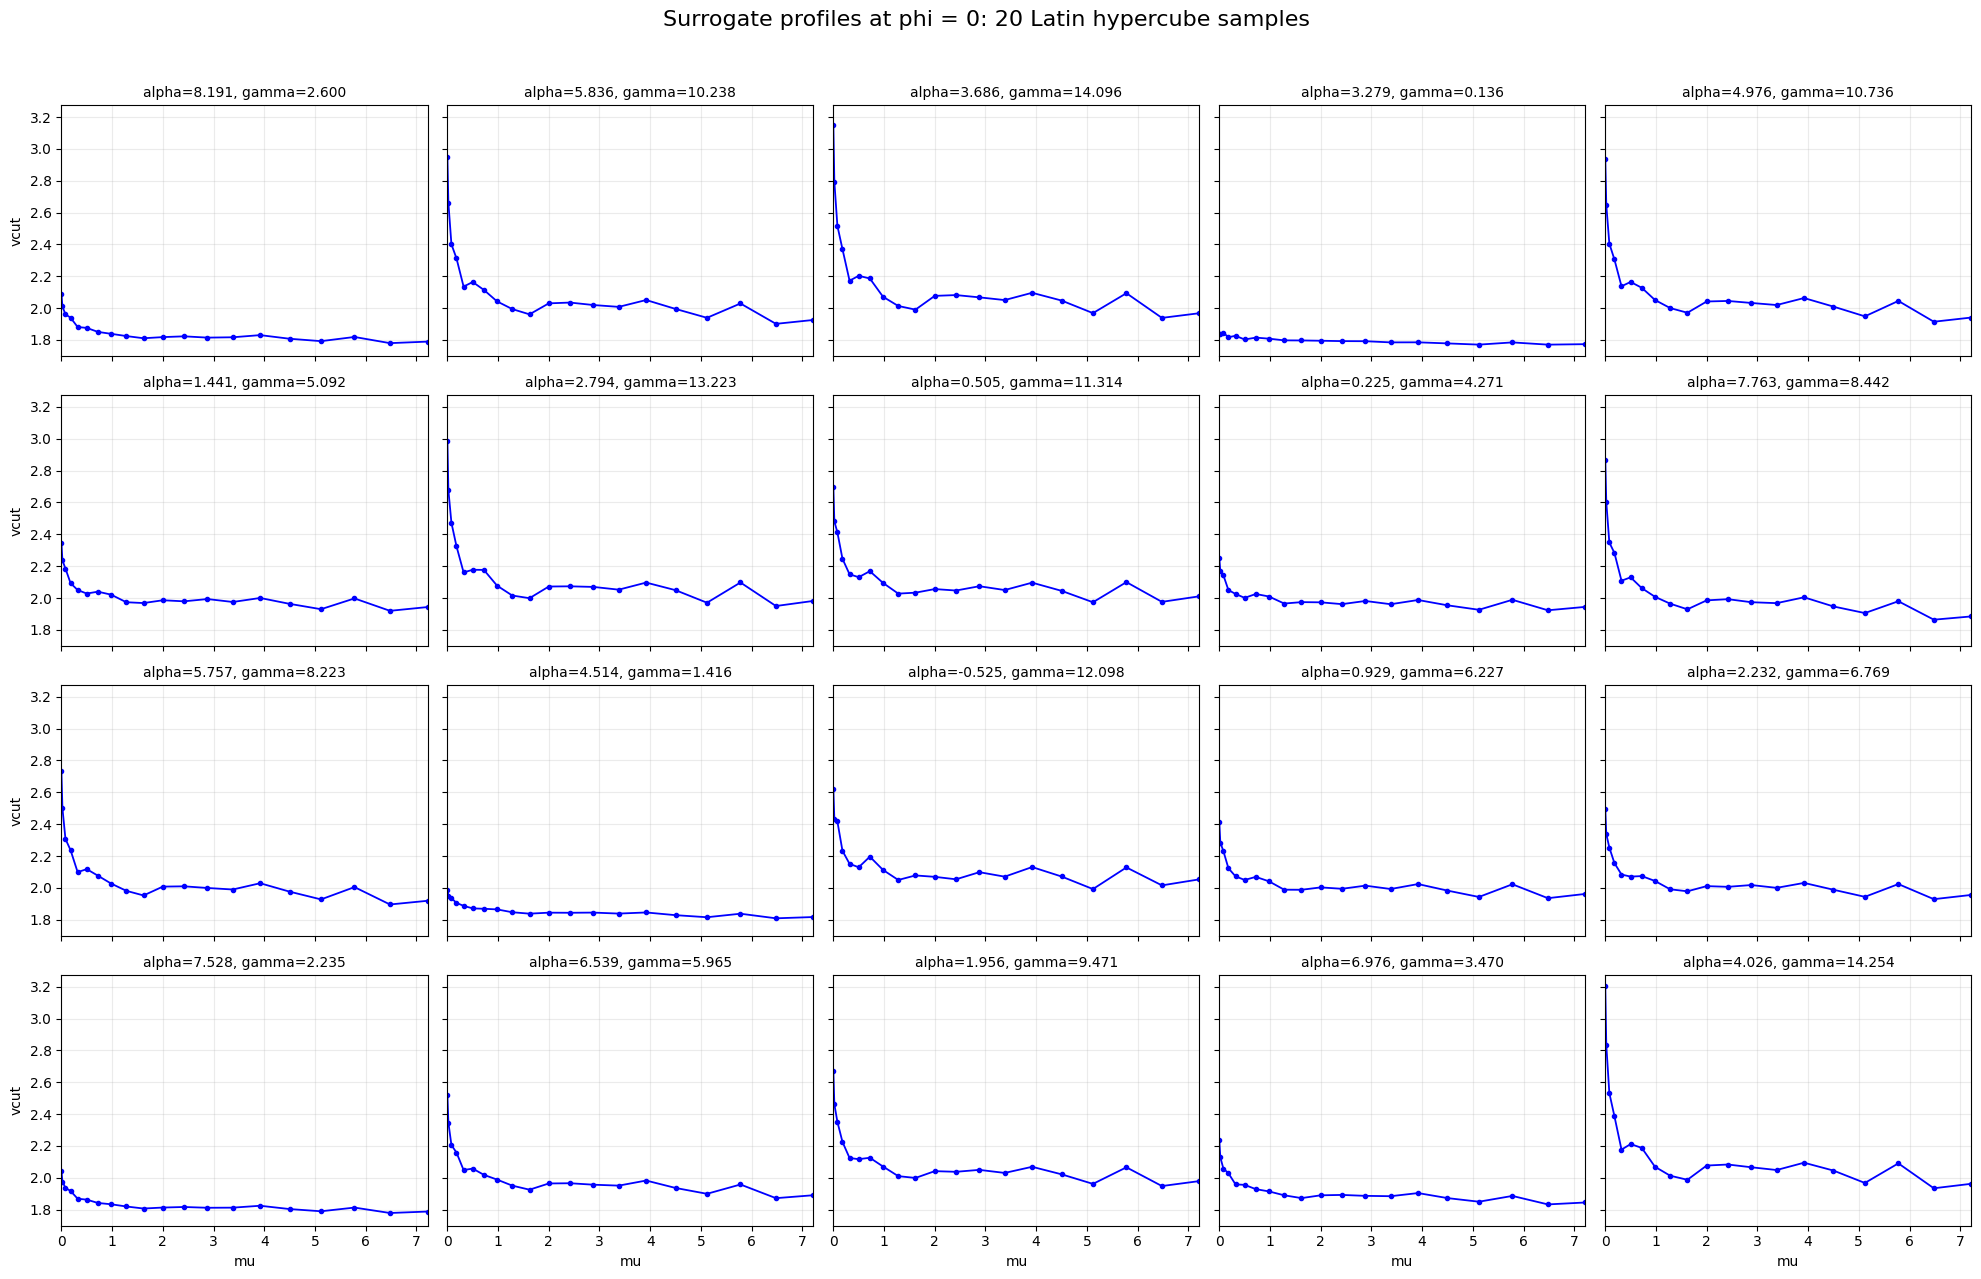

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import qmc
from gyraze_conv_MPE_surrogate import surrogate_model, vvec as mu_grid

# Run the 3D boundary cell first to define the current plot_bounds.
# Edit the fixed variable/value; the other two are Latin hypercube sampled.
fixed_variable = "phi"  # "alpha", "gamma", or "phi"
fixed_value = 0.0
profile_seed = 101326  # Change for a different set of parameter combinations.
sample_count = 20

parameter_names = ["alpha", "gamma", "phi"]
if fixed_variable not in parameter_names:
    raise ValueError(f"Choose one of {parameter_names}.")
fixed_index = parameter_names.index(fixed_variable)
if not plot_bounds[fixed_index, 0] <= fixed_value <= plot_bounds[fixed_index, 1]:
    raise ValueError(f"{fixed_variable} must be within {plot_bounds[fixed_index].tolist()}.")
sampled_indices = [i for i in range(3) if i != fixed_index]
parameter_bounds = plot_bounds[sampled_indices]
sampler = qmc.LatinHypercube(d=2, seed=profile_seed)
parameter_samples = qmc.scale(sampler.random(sample_count),
                              parameter_bounds[:, 0], parameter_bounds[:, 1])
profile_inputs = np.empty((sample_count, 3))  # alpha, gamma, phi
profile_inputs[:, fixed_index] = fixed_value
profile_inputs[:, sampled_indices] = parameter_samples
profile_predictions = np.array([
    surrogate_model(mu_grid, *parameters) for parameters in profile_inputs
])

fig_lhs, axes_lhs = plt.subplots(4, 5, figsize=(20, 13), sharex=True, sharey=True)
for profile_ax, parameters, vcuts in zip(axes_lhs.flat, profile_inputs, profile_predictions):
    profile_ax.plot(mu_grid, vcuts, "o-", color="blue", markersize=3, linewidth=1.3)
    profile_ax.set_title(
        ", ".join(f"{parameter_names[i]}={parameters[i]:.3f}" for i in sampled_indices),
        fontsize=10
    )
    profile_ax.set_xlim(mu_grid[0], mu_grid[-1])
    profile_ax.grid(alpha=0.25)
for profile_ax in axes_lhs[-1, :]:
    profile_ax.set_xlabel("mu")
for profile_ax in axes_lhs[:, 0]:
    profile_ax.set_ylabel("vcut")
fig_lhs.suptitle(
    f"Surrogate profiles at {fixed_variable} = {fixed_value:g}: 20 Latin hypercube samples",
    fontsize=16
)
fig_lhs.tight_layout(rect=(0, 0, 1, 0.96))
for i, bounds in zip(sampled_indices, parameter_bounds):
    print(f"{parameter_names[i]} sampled within {bounds.tolist()}.")
plt.show()


1566 converged points; minimum phi_wall = 0.37348.


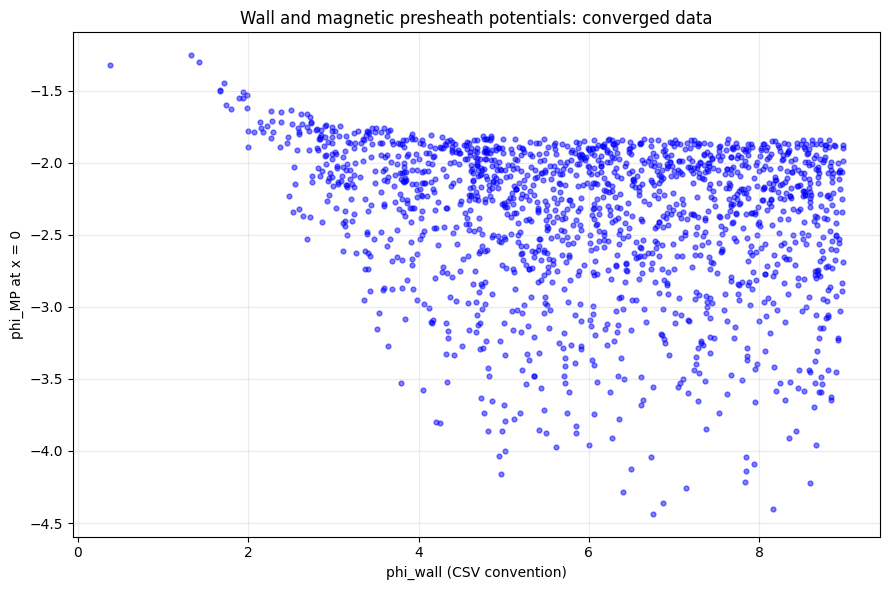

In [8]:
import pandas as pd
import matplotlib.pyplot as plt

# Use the original CSV: v1 = 0 marks failed convergence in this dataset.
original_data = pd.read_csv("combined.csv")
converged_potentials = original_data.loc[
    original_data["v1"].notna() & (original_data["v1"] != 0),
    ["phi_wall", "phi_MP"]
].dropna()
fig_potentials, ax_potentials = plt.subplots(figsize=(9, 6))
ax_potentials.scatter(converged_potentials["phi_wall"], converged_potentials["phi_MP"],
                      s=12, color="blue", alpha=0.5)
ax_potentials.set_xlabel("phi_wall (CSV convention)")
ax_potentials.set_ylabel("phi_MP at x = 0")
ax_potentials.set_title("Wall and magnetic presheath potentials: converged data")
ax_potentials.grid(alpha=0.25)
fig_potentials.tight_layout()
print(f"{len(converged_potentials)} converged points; "
      f"minimum phi_wall = {converged_potentials.phi_wall.min():.6g}.")
plt.show()


1566 converged profiles; zero RMS deviation means a flat profile.


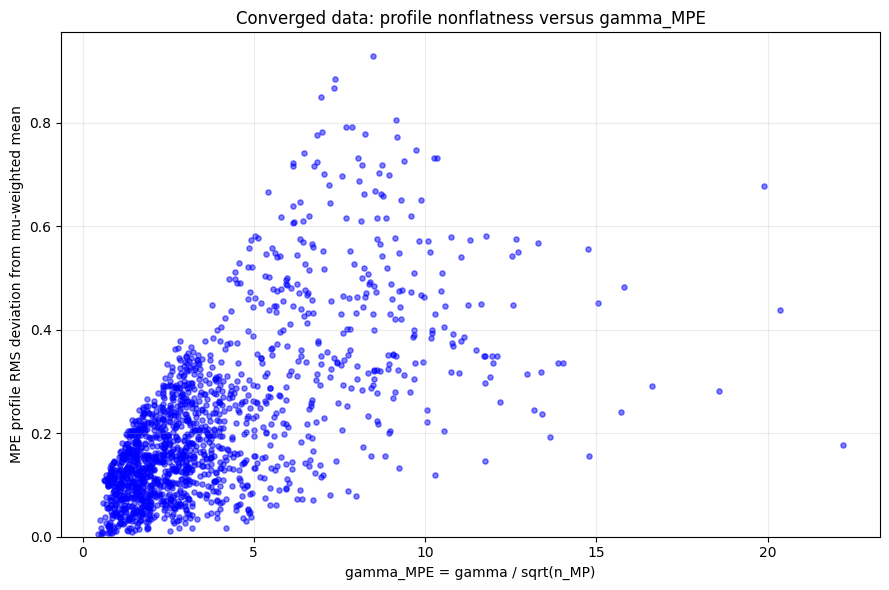

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from gyraze_conv_MPE_surrogate import vvec as mu_grid

# Original v1 != 0 identifies converged rows; analyze their MPE profiles.
original_data = pd.read_csv("combined.csv")
velocity_columns = [f"v{i}" for i in range(1, 21)]
converged_profiles = original_data.loc[
    original_data["v1"].notna() & (original_data["v1"] != 0)
].dropna(subset=["gamma", "n_MP", "phi_MP"] + velocity_columns).copy()
assert (converged_profiles["n_MP"] > 0).all()
gamma_mpe = converged_profiles["gamma"].to_numpy() / np.sqrt(converged_profiles["n_MP"].to_numpy())
radicands = converged_profiles[velocity_columns].to_numpy()**2 - 2 * converged_profiles["phi_MP"].to_numpy()[:, None]
assert (radicands >= 0).all()
mpe_profiles = np.sqrt(radicands)

# Trapezoidal weights avoid over-weighting the densely spaced low-mu samples.
mu_steps = np.diff(mu_grid)
mu_weights = np.r_[mu_steps[0] / 2, (mu_steps[:-1] + mu_steps[1:]) / 2, mu_steps[-1] / 2]
mu_weights = mu_weights / (mu_grid[-1] - mu_grid[0])
mean_vcut = mpe_profiles @ mu_weights
profile_variance = ((mpe_profiles - mean_vcut[:, None])**2) @ mu_weights
flatness_rms = np.sqrt(profile_variance)  # Zero is perfectly flat.
flatness_data = pd.DataFrame({
    "gamma_MPE": gamma_mpe,
    "mean_vcut": mean_vcut,
    "profile_variance": profile_variance,
    "flatness_rms": flatness_rms,
}, index=converged_profiles.index)

fig_flatness, ax_flatness = plt.subplots(figsize=(9, 6))
ax_flatness.scatter(flatness_data["gamma_MPE"], flatness_data["flatness_rms"],
                    color="blue", s=14, alpha=0.5)
ax_flatness.set_xlabel("gamma_MPE = gamma / sqrt(n_MP)")
ax_flatness.set_ylabel("MPE profile RMS deviation from mu-weighted mean")
ax_flatness.set_title("Converged data: profile nonflatness versus gamma_MPE")
ax_flatness.set_ylim(bottom=0)
ax_flatness.grid(alpha=0.25)
fig_flatness.tight_layout()
print(f"{len(flatness_data)} converged profiles; zero RMS deviation means a flat profile.")
plt.show()


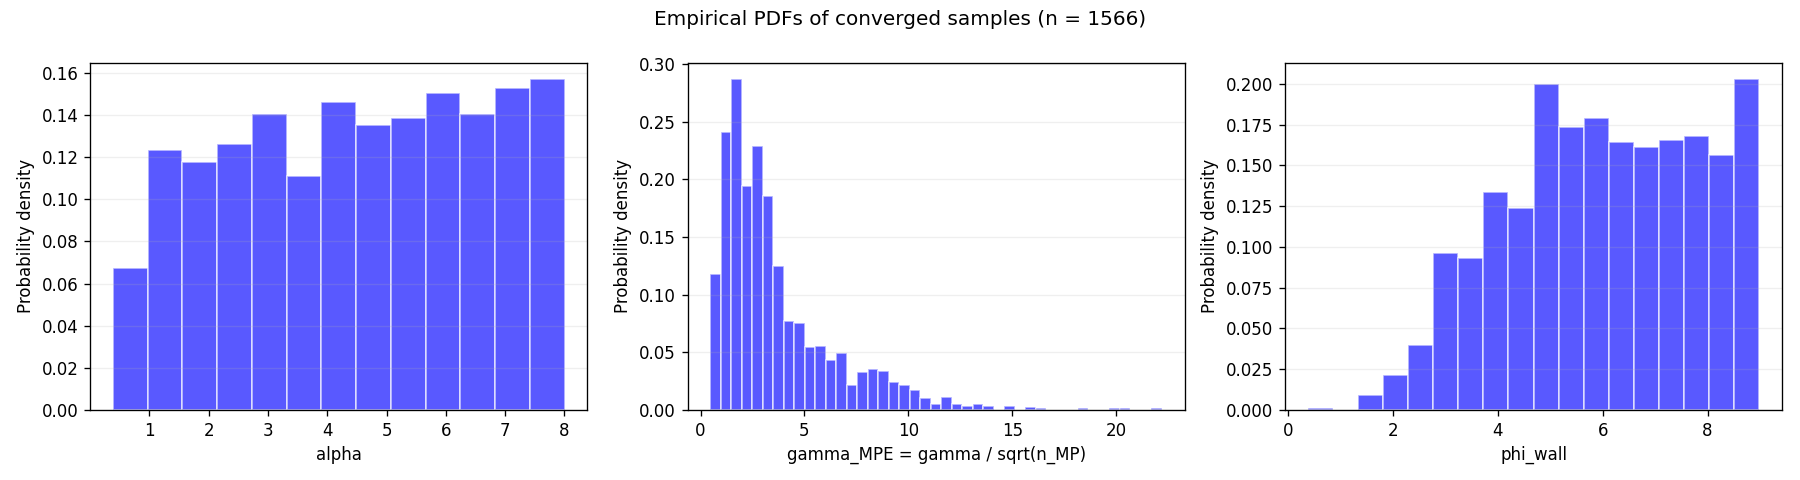

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Use original v1 to select converged samples before transforming gamma.
pdf_source = pd.read_csv("combined.csv")
pdf_samples = pdf_source.loc[
    pdf_source["v1"].notna() & (pdf_source["v1"] != 0)
].dropna(subset=["alpha", "gamma", "phi_wall", "n_MP"]).copy()
assert (pdf_samples["n_MP"] > 0).all()
pdf_samples["gamma_MPE"] = pdf_samples["gamma"] / np.sqrt(pdf_samples["n_MP"])

fig_pdfs, axes_pdfs = plt.subplots(1, 3, figsize=(15, 4))
for pdf_ax, column, label in zip(
    axes_pdfs,
    ["alpha", "gamma_MPE", "phi_wall"],
    ["alpha", "gamma_MPE = gamma / sqrt(n_MP)", "phi_wall"],
):
    pdf_ax.hist(pdf_samples[column], bins="fd", density=True,
                color="blue", alpha=0.65, edgecolor="white")
    pdf_ax.set_xlabel(label)
    pdf_ax.set_ylabel("Probability density")
    pdf_ax.grid(axis="y", alpha=0.2)
fig_pdfs.suptitle(f"Empirical PDFs of converged samples (n = {len(pdf_samples)})")
fig_pdfs.tight_layout()
plt.show()
